In [37]:
print("Contents of ChurnProject:")
for item in os.listdir('/content/drive/MyDrive/ChurnProject'):
    print(item)

Contents of ChurnProject:


NameError: name 'os' is not defined

In [38]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load dataset from Google Drive permanently
df = pd.read_csv('/content/drive/MyDrive/ChurnProject/churn_data.csv.csv')

# Create TenureGroup column
df['TenureGroup'] = pd.cut(df['tenure'],
                            bins=[0, 12, 24, 48, 60, 72],
                            labels=['0-12 months', '12-24 months',
                                    '24-48 months', '48-60 months', '60-72 months'])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Shape: (7043, 22)


In [39]:


# First look
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (7043, 22)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,24-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,24-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months


In [40]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
# Basic info
print("Dataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   object  
 1   gender            7043 non-null   object  
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   object  
 4   Dependents        7043 non-null   object  
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   object  
 7   MultipleLines     7043 non-null   object  
 8   InternetService   7043 non-null   object  
 9   OnlineSecurity    7043 non-null   object  
 10  OnlineBackup      7043 non-null   object  
 11  DeviceProtection  7043 non-null   object  
 12  TechSupport       7043 non-null   object  
 13  StreamingTV       7043 non-null   object  
 14  StreamingMovies   7043 non-null   object  
 15  Contract          7043 non-null   object  
 16  PaperlessB

In [42]:
# Separate columns by type for reference
categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("\nNumerical Columns:", numerical_cols)


Categorical Columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

Numerical Columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']


In [43]:
# Statistical summary
print("Statistical Summary:")
df.describe()


Statistical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [44]:
# Check unique values in categorical columns
print("Unique values in each categorical column:\n")
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values → {df[col].unique()}")

Unique values in each categorical column:

customerID: 7043 unique values → ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender: 2 unique values → ['Female' 'Male']
Partner: 2 unique values → ['Yes' 'No']
Dependents: 2 unique values → ['No' 'Yes']
PhoneService: 2 unique values → ['No' 'Yes']
MultipleLines: 3 unique values → ['No phone service' 'No' 'Yes']
InternetService: 3 unique values → ['DSL' 'Fiber optic' 'No']
OnlineSecurity: 3 unique values → ['No' 'Yes' 'No internet service']
OnlineBackup: 3 unique values → ['Yes' 'No' 'No internet service']
DeviceProtection: 3 unique values → ['No' 'Yes' 'No internet service']
TechSupport: 3 unique values → ['No' 'Yes' 'No internet service']
StreamingTV: 3 unique values → ['No' 'Yes' 'No internet service']
StreamingMovies: 3 unique values → ['No' 'Yes' 'No internet service']
Contract: 3 unique values → ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: 2 unique values → ['Yes' 'No']
PaymentMethod

In [45]:
# Check SeniorCitizen column
print("SeniorCitizen Value Counts:")
print(df['SeniorCitizen'].value_counts())
print("\nNote: 0 = Not Senior, 1 = Senior")

SeniorCitizen Value Counts:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Note: 0 = Not Senior, 1 = Senior


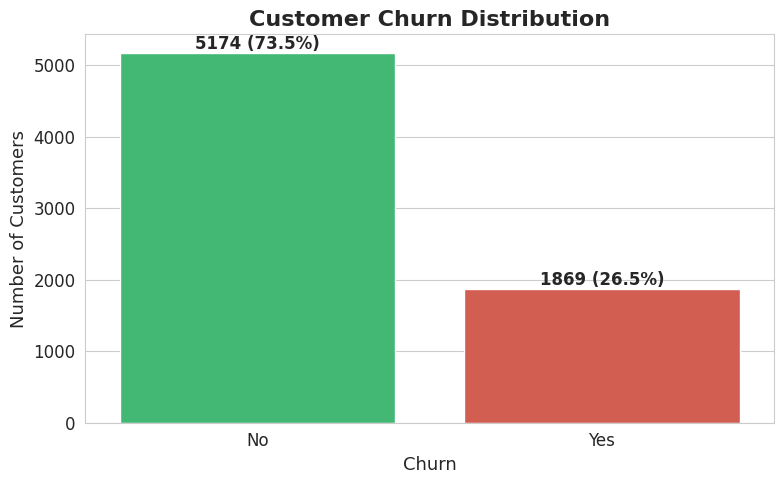

Plot saved!


In [46]:
# Set style for all plots
sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Plot 1 — Churn Distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Customer Churn Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Churn', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)

# Add count labels on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({int(p.get_height())/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

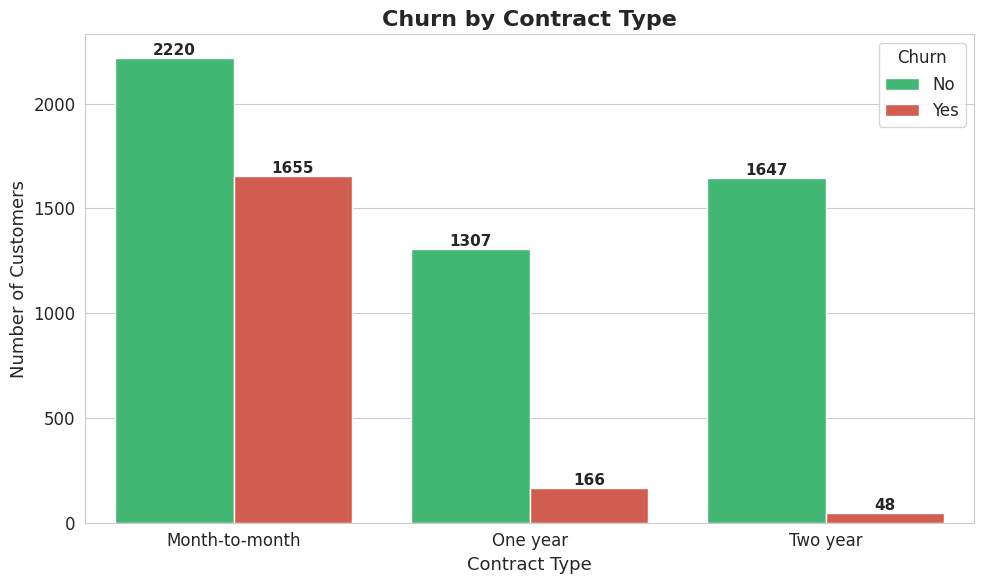

Plot saved!


In [47]:
# Plot 2 — Churn by Contract Type
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Contract', hue='Churn',
                   palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Contract Type', fontsize=16, fontweight='bold')
plt.xlabel('Contract Type', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)
plt.legend(title='Churn', labels=['No', 'Yes'])

# Add count labels on bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

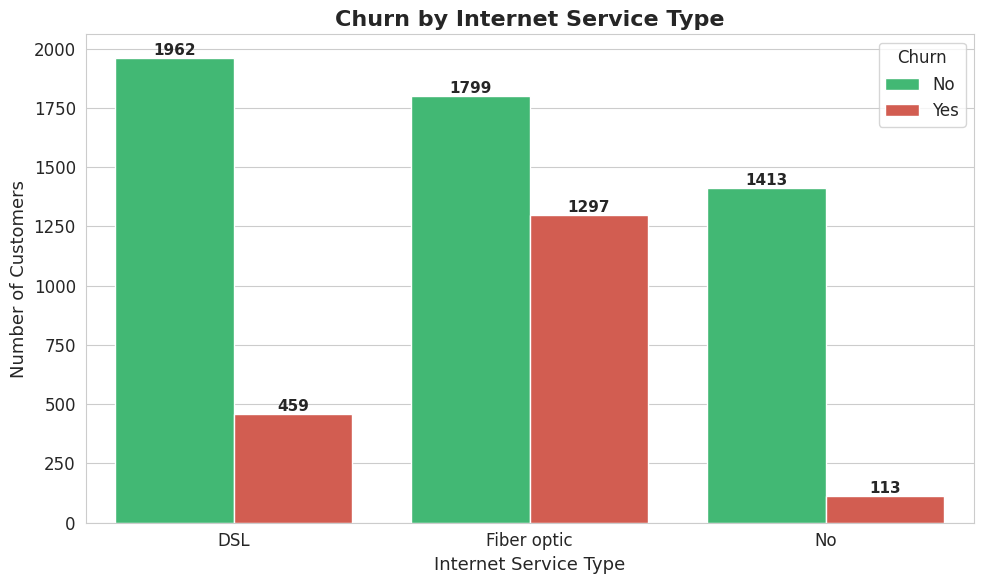

Plot saved!


In [48]:
# Plot 3 — Churn by Internet Service
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='InternetService', hue='Churn',
                   palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Internet Service Type', fontsize=16, fontweight='bold')
plt.xlabel('Internet Service Type', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)
plt.legend(title='Churn', labels=['No', 'Yes'])

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_by_internet_service.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

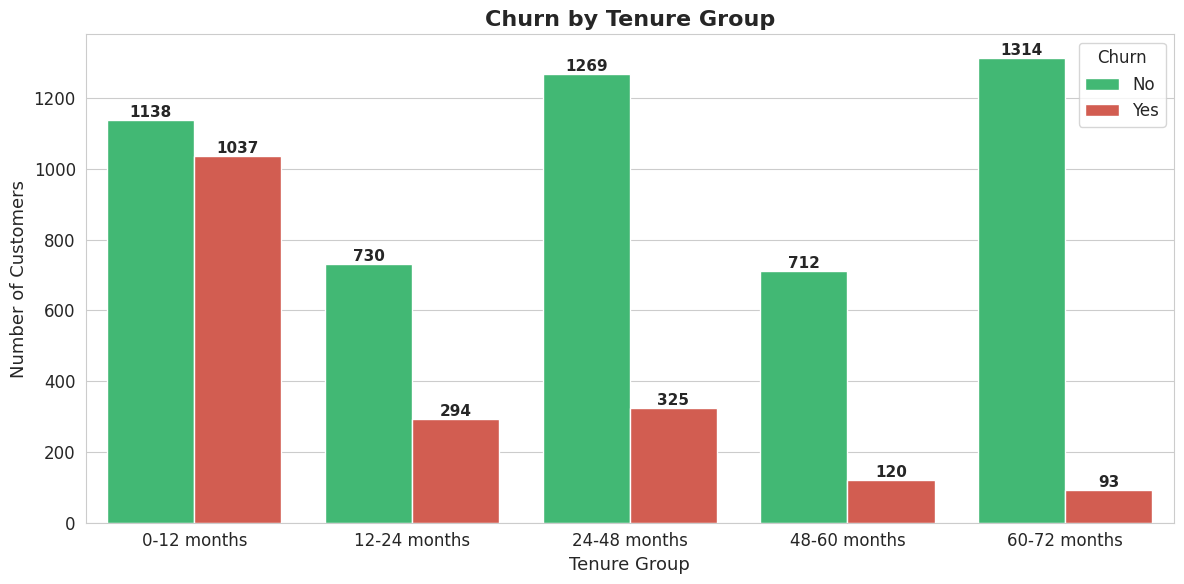

Plot saved!


In [49]:
# Plot 4 — Churn by Tenure Group
# First create tenure groups
df['TenureGroup'] = pd.cut(df['tenure'],
                            bins=[0, 12, 24, 48, 60, 72],
                            labels=['0-12 months', '12-24 months',
                                    '24-48 months', '48-60 months', '60-72 months'])

plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, x='TenureGroup', hue='Churn',
                   palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Tenure Group', fontsize=16, fontweight='bold')
plt.xlabel('Tenure Group', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)
plt.legend(title='Churn', labels=['No', 'Yes'])

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_by_tenure.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

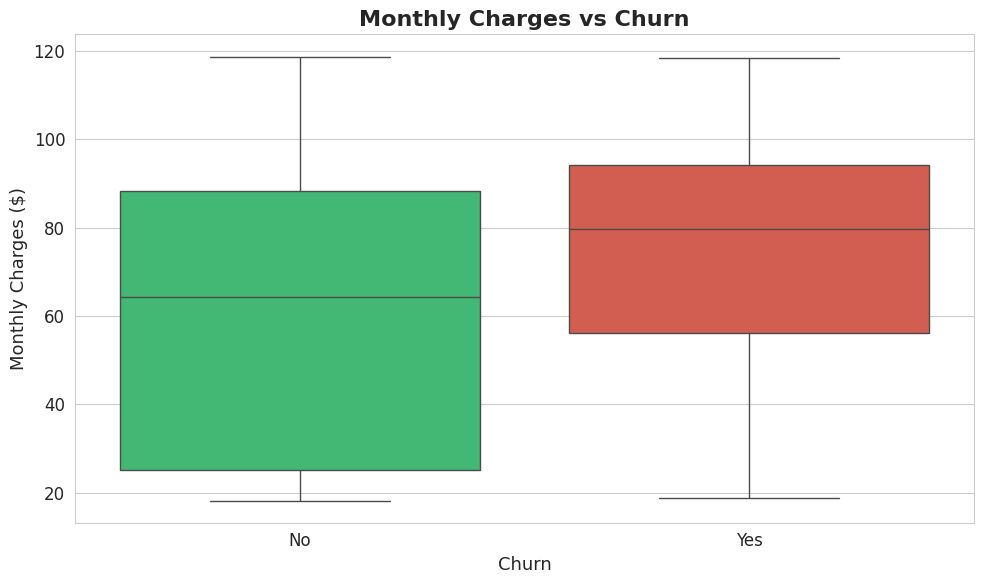

Plot saved!


In [50]:
# Plot 5 — Monthly Charges vs Churn
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges',
            palette=['#2ecc71', '#e74c3c'])
plt.title('Monthly Charges vs Churn', fontsize=16, fontweight='bold')
plt.xlabel('Churn', fontsize=13)
plt.ylabel('Monthly Charges ($)', fontsize=13)

plt.tight_layout()
plt.savefig('monthly_charges_vs_churn.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

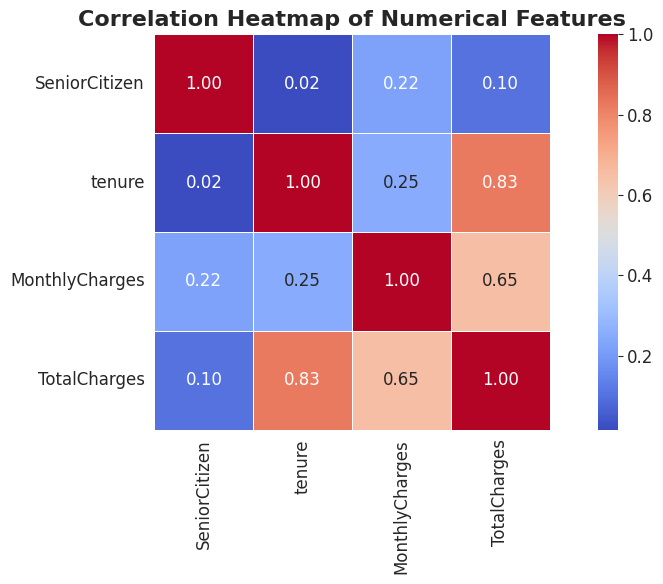

Plot saved!


In [51]:
# Plot 6 — Correlation Heatmap
plt.figure(figsize=(10, 6))

# Convert TotalCharges to numeric for correlation
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Select numerical columns including TotalCharges
corr_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, square=True)
plt.title('Correlation Heatmap of Numerical Features', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

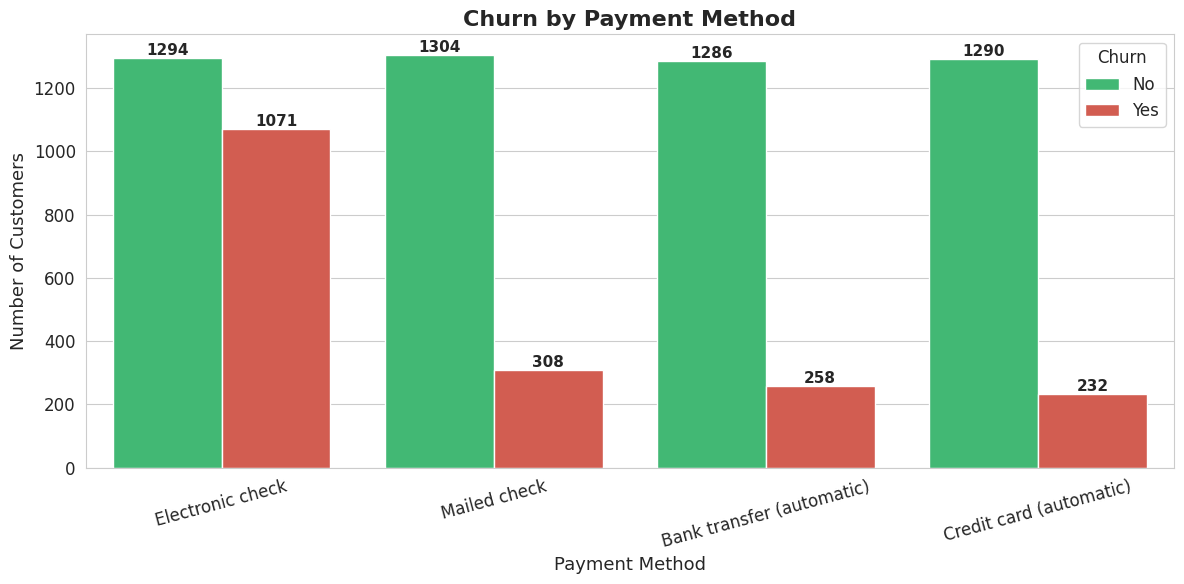

Plot saved!


In [52]:
# Plot 7 — Churn by Payment Method
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, x='PaymentMethod', hue='Churn',
                   palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Payment Method', fontsize=16, fontweight='bold')
plt.xlabel('Payment Method', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)
plt.xticks(rotation=15)
plt.legend(title='Churn', labels=['No', 'Yes'])

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_by_payment.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

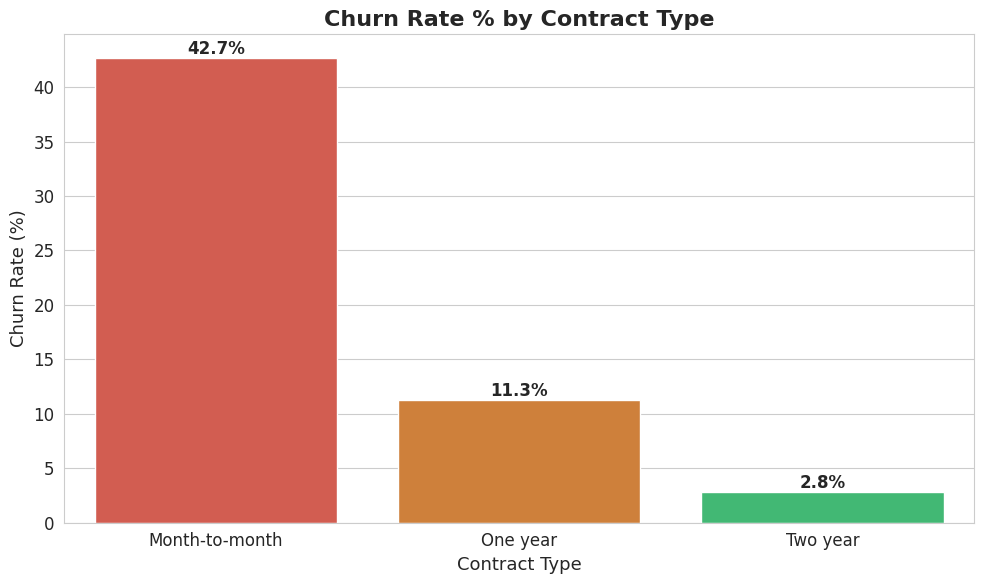

Plot saved!


In [53]:
# Plot 1 — Churn Rate Percentage by Contract Type
plt.figure(figsize=(10, 6))

contract_churn = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100).reset_index()
contract_churn.columns = ['Contract', 'Churn Rate %']

ax = sns.barplot(data=contract_churn, x='Contract', y='Churn Rate %',
                 palette=['#e74c3c', '#e67e22', '#2ecc71'])
plt.title('Churn Rate % by Contract Type', fontsize=16, fontweight='bold')
plt.xlabel('Contract Type', fontsize=13)
plt.ylabel('Churn Rate (%)', fontsize=13)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_rate_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

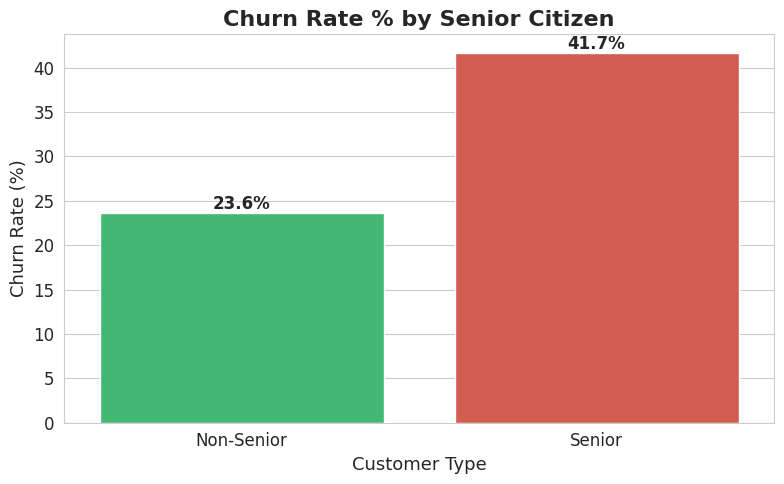

Plot saved!


In [54]:
# Plot 2 — Churn Rate by Senior Citizen
plt.figure(figsize=(8, 5))

senior_churn = df.groupby('SeniorCitizen')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100).reset_index()
senior_churn.columns = ['SeniorCitizen', 'Churn Rate %']
senior_churn['SeniorCitizen'] = senior_churn['SeniorCitizen'].map({0: 'Non-Senior', 1: 'Senior'})

ax = sns.barplot(data=senior_churn, x='SeniorCitizen', y='Churn Rate %',
                 palette=['#2ecc71', '#e74c3c'])
plt.title('Churn Rate % by Senior Citizen', fontsize=16, fontweight='bold')
plt.xlabel('Customer Type', fontsize=13)
plt.ylabel('Churn Rate (%)', fontsize=13)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_rate_by_senior.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

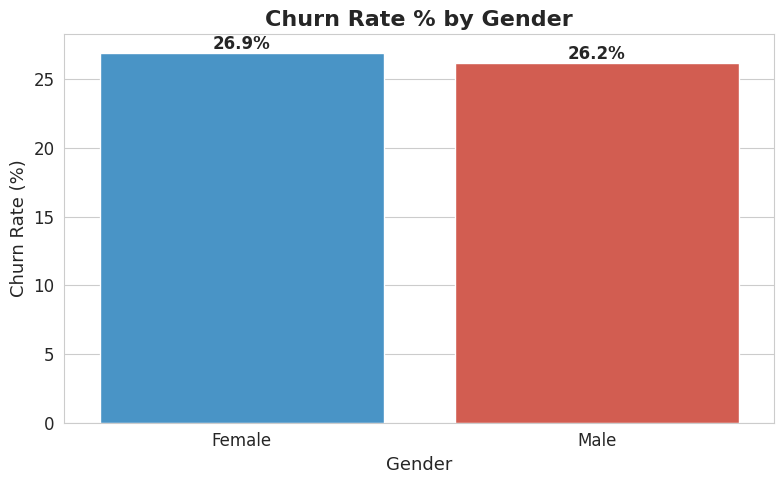

Plot saved!


In [55]:
# Plot 3 — Churn Rate by Gender
plt.figure(figsize=(8, 5))

gender_churn = df.groupby('gender')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100).reset_index()
gender_churn.columns = ['Gender', 'Churn Rate %']

ax = sns.barplot(data=gender_churn, x='Gender', y='Churn Rate %',
                 palette=['#3498db', '#e74c3c'])
plt.title('Churn Rate % by Gender', fontsize=16, fontweight='bold')
plt.xlabel('Gender', fontsize=13)
plt.ylabel('Churn Rate (%)', fontsize=13)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_rate_by_gender.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

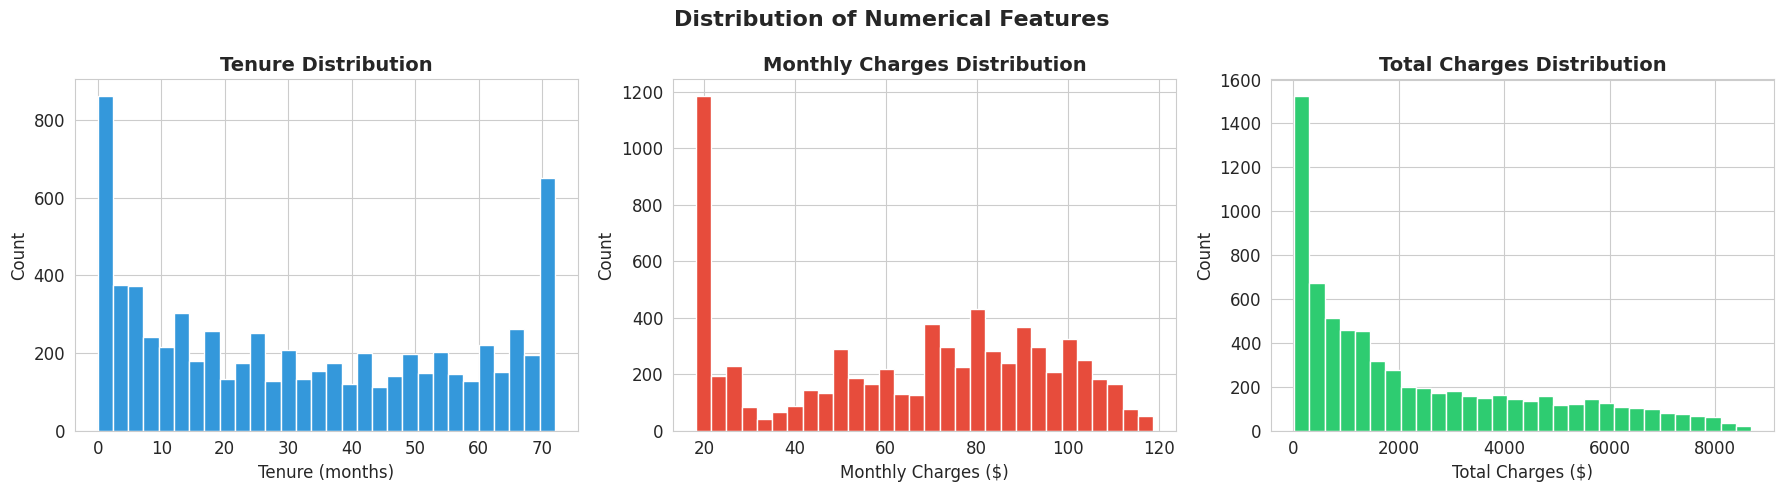

Plot saved!


In [56]:
# Plot 4 — Distribution of Numerical Features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Tenure distribution
axes[0].hist(df['tenure'], bins=30, color='#3498db', edgecolor='white')
axes[0].set_title('Tenure Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Count')

# Monthly Charges distribution
axes[1].hist(df['MonthlyCharges'], bins=30, color='#e74c3c', edgecolor='white')
axes[1].set_title('Monthly Charges Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Monthly Charges ($)')
axes[1].set_ylabel('Count')

# Total Charges distribution
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
axes[2].hist(df['TotalCharges'].dropna(), bins=30, color='#2ecc71', edgecolor='white')
axes[2].set_title('Total Charges Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Total Charges ($)')
axes[2].set_ylabel('Count')

plt.suptitle('Distribution of Numerical Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('numerical_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

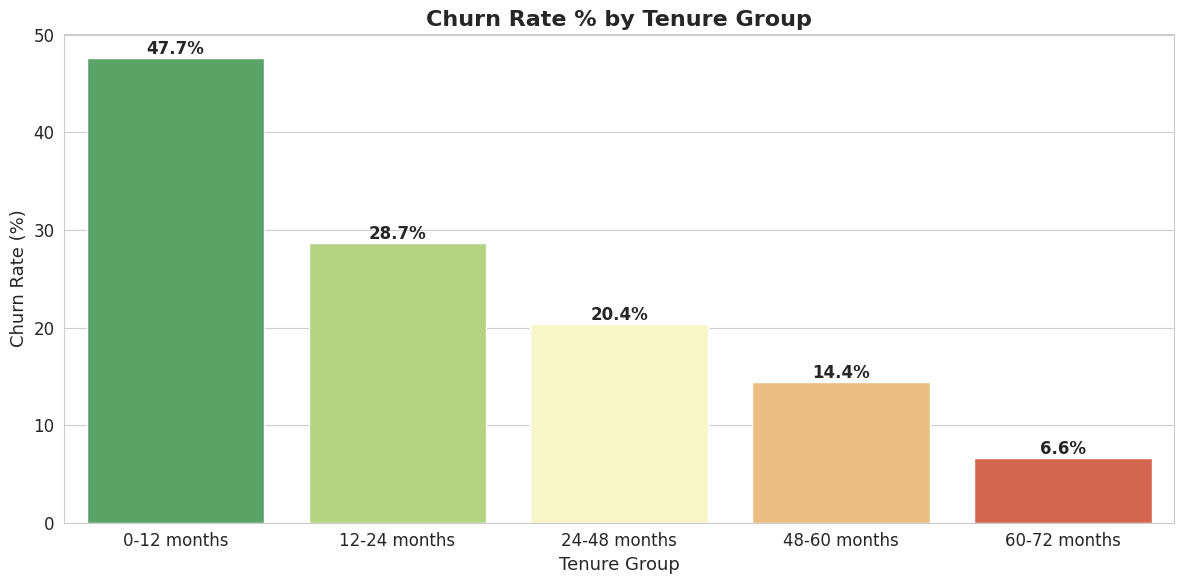

Plot saved!


In [57]:
# Plot 5 — Churn Rate % by Tenure Group
plt.figure(figsize=(12, 6))

tenure_churn = df.groupby('TenureGroup')['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100).reset_index()
tenure_churn.columns = ['TenureGroup', 'Churn Rate %']

ax = sns.barplot(data=tenure_churn, x='TenureGroup', y='Churn Rate %',
                 palette='RdYlGn_r')
plt.title('Churn Rate % by Tenure Group', fontsize=16, fontweight='bold')
plt.xlabel('Tenure Group', fontsize=13)
plt.ylabel('Churn Rate (%)', fontsize=13)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('churn_rate_by_tenure_group.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")


In [58]:
# Step 1 — Fix TotalCharges and Drop Unnecessary Columns

# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many NaN values were created
print("NaN values in TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

# Fill NaN values with median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Drop customerID as it adds no predictive value
df.drop(columns=['customerID'], inplace=True)

# Drop TenureGroup as it was just for visualization
df.drop(columns=['TenureGroup'], inplace=True)

print("Columns after dropping unnecessary ones:")
print(df.columns.tolist())
print("\nShape:", df.shape)

NaN values in TotalCharges after conversion: 11
Columns after dropping unnecessary ones:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Shape: (7043, 20)


In [59]:
# Step 2 — Encode Binary Categorical Columns
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Binary columns to encode
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

for col in binary_cols:
    df[col] = le.fit_transform(df[col])
    print(f"{col} encoded: {df[col].unique()}")

print("\nShape after binary encoding:", df.shape)
print("\nFirst 3 rows:")
df.head(3)

gender encoded: [0 1]
Partner encoded: [1 0]
Dependents encoded: [0 1]
PhoneService encoded: [0 1]
PaperlessBilling encoded: [1 0]
Churn encoded: [0 1]

Shape after binary encoding: (7043, 20)

First 3 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1


In [60]:
# Step 3 — One Hot Encoding for Multi-Category Columns
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

print("Shape after One Hot Encoding:", df.shape)
print("\nAll columns after encoding:")
print(df.columns.tolist())

Shape after One Hot Encoding: (7043, 31)

All columns after encoding:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [61]:
# Step 4 — Feature Scaling
from sklearn.preprocessing import StandardScaler

# Define features and target
X = df.drop(columns=['Churn'])
y = df['Churn']

# Scale numerical columns
scaler = StandardScaler()
numerical = ['tenure', 'MonthlyCharges', 'TotalCharges']
X[numerical] = scaler.fit_transform(X[numerical])

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSample of scaled numerical columns:")
X[numerical].head(3)

Features shape: (7043, 30)
Target shape: (7043,)

Sample of scaled numerical columns:


,tenure,MonthlyCharges,TotalCharges
0,-1.277445,-1.160323,-0.994242
1,0.066327,-0.259629,-0.173244
2,-1.236724,-0.362660,-0.959674


In [62]:
# Step 5 — Handle Class Imbalance using SMOTE
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Before SMOTE:")
print(Counter(y))

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nAfter SMOTE:")
print(Counter(y_resampled))
print("\nShape after SMOTE:")
print("X:", X_resampled.shape)
print("y:", y_resampled.shape)

Before SMOTE:
Counter({0: 5174, 1: 1869})

After SMOTE:
Counter({0: 5174, 1: 5174})

Shape after SMOTE:
X: (10348, 30)
y: (10348,)


In [63]:
# Step 6 — Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled,
    test_size=0.2,
    random_state=42,
    stratify=y_resampled)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("\nTraining target distribution:")
print(Counter(y_train))
print("\nTesting target distribution:")
print(Counter(y_test))

Training set size: (8278, 30)
Testing set size: (2070, 30)

Training target distribution:
Counter({1: 4139, 0: 4139})

Testing target distribution:
Counter({0: 1035, 1: 1035})


MODEL BUILDING




In [64]:
# Model 1 — Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Train model
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

# Evaluate
print("=== Logistic Regression Results ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

=== Logistic Regression Results ===
Accuracy:  0.7932
Precision: 0.7679
Recall:    0.8406
F1 Score:  0.8026
ROC-AUC:   0.8818


In [65]:
# Model 2 — Random Forest
from sklearn.ensemble import RandomForestClassifier

# Train model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Evaluate
print("=== Random Forest Results ===")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_rf), 4))

=== Random Forest Results ===
Accuracy:  0.8449
Precision: 0.8251
Recall:    0.8754
F1 Score:  0.8495
ROC-AUC:   0.9194


In [66]:
# Model 3 — XGBoost
from xgboost import XGBClassifier

# Train model
xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

# Evaluate
print("=== XGBoost Results ===")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_xgb), 4))
print("F1 Score: ", round(f1_score(y_test, y_pred_xgb), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_xgb), 4))

=== XGBoost Results ===
Accuracy:  0.8271
Precision: 0.8086
Recall:    0.857
F1 Score:  0.8321
ROC-AUC:   0.9059


**Model Evaluation**

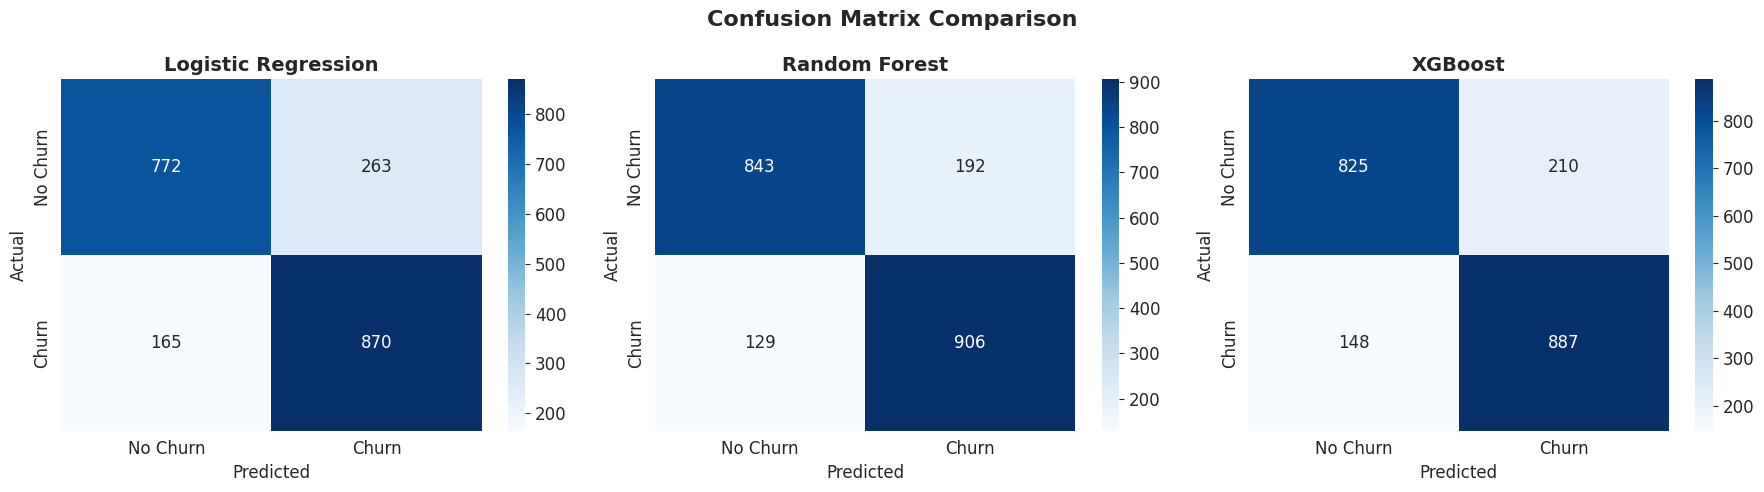

Plot saved!


In [67]:
# Confusion Matrix for all 3 models
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ('Logistic Regression', y_pred_lr),
    ('Random Forest', y_pred_rf),
    ('XGBoost', y_pred_xgb)
]

for ax, (name, y_pred) in zip(axes, models):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'], ax=ax)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('Actual', fontsize=12)

plt.suptitle('Confusion Matrix Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

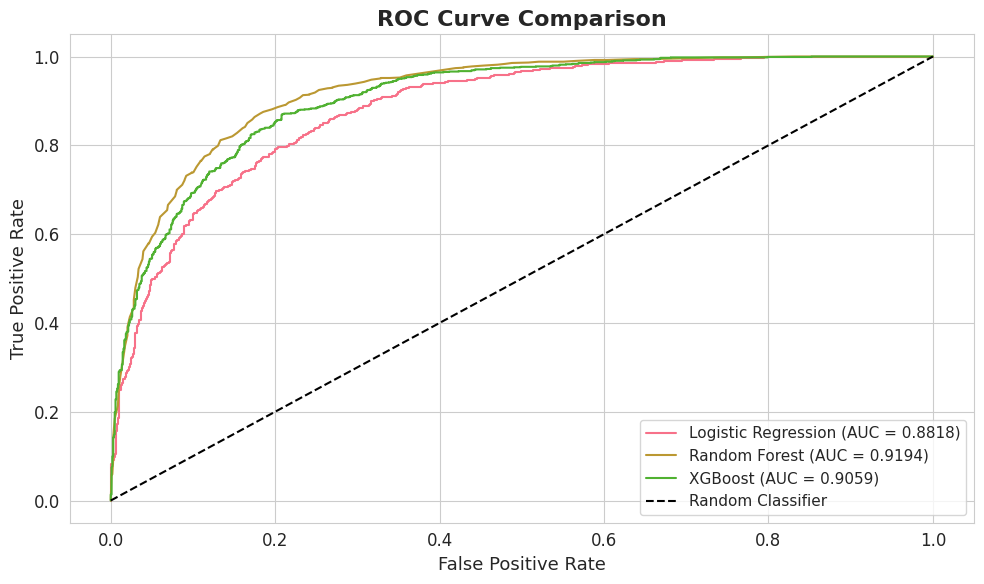

Plot saved!


In [68]:
# ROC Curve for all 3 models
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 6))

models_roc = [
    ('Logistic Regression', y_prob_lr, 0.8818),
    ('Random Forest', y_prob_rf, 0.9194),
    ('XGBoost', y_prob_xgb, 0.9059)
]

for name, y_prob, auc in models_roc:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name + ' (AUC = ' + str(auc) + ')')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.title('ROC Curve Comparison', fontsize=16, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

In [69]:
# Final Model Comparison Summary
import pandas as pd

results = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [0.7932, 0.8449, 0.8271],
    'Precision': [0.7679, 0.8251, 0.8086],
    'Recall': [0.8406, 0.8754, 0.8570],
    'F1 Score': [0.8026, 0.8495, 0.8321],
    'ROC-AUC': [0.8818, 0.9194, 0.9059]
}

results_df = pd.DataFrame(results)
print("=== Final Model Comparison ===")
print(results_df.to_string(index=False))
print()
print("Best Model: Random Forest")
print("Best Accuracy:", 0.8449)
print("Best ROC-AUC:", 0.9194)

=== Final Model Comparison ===
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7932     0.7679  0.8406    0.8026   0.8818
      Random Forest    0.8449     0.8251  0.8754    0.8495   0.9194
            XGBoost    0.8271     0.8086  0.8570    0.8321   0.9059

Best Model: Random Forest
Best Accuracy: 0.8449
Best ROC-AUC: 0.9194


In [70]:
# Feature Importance from Random Forest
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("Top 15 Most Important Features:")
print(feature_importance.head(15).to_string(index=False))

Top 15 Most Important Features:
                       Feature  Importance
                  TotalCharges    0.176516
                        tenure    0.170515
                MonthlyCharges    0.146250
PaymentMethod_Electronic check    0.059749
             Contract_Two year    0.047515
   InternetService_Fiber optic    0.045706
                        gender    0.025286
             Contract_One year    0.024173
              PaperlessBilling    0.023310
                       Partner    0.022547
            OnlineSecurity_Yes    0.021823
                    Dependents    0.021584
               TechSupport_Yes    0.019904
              OnlineBackup_Yes    0.019282
             MultipleLines_Yes    0.019139


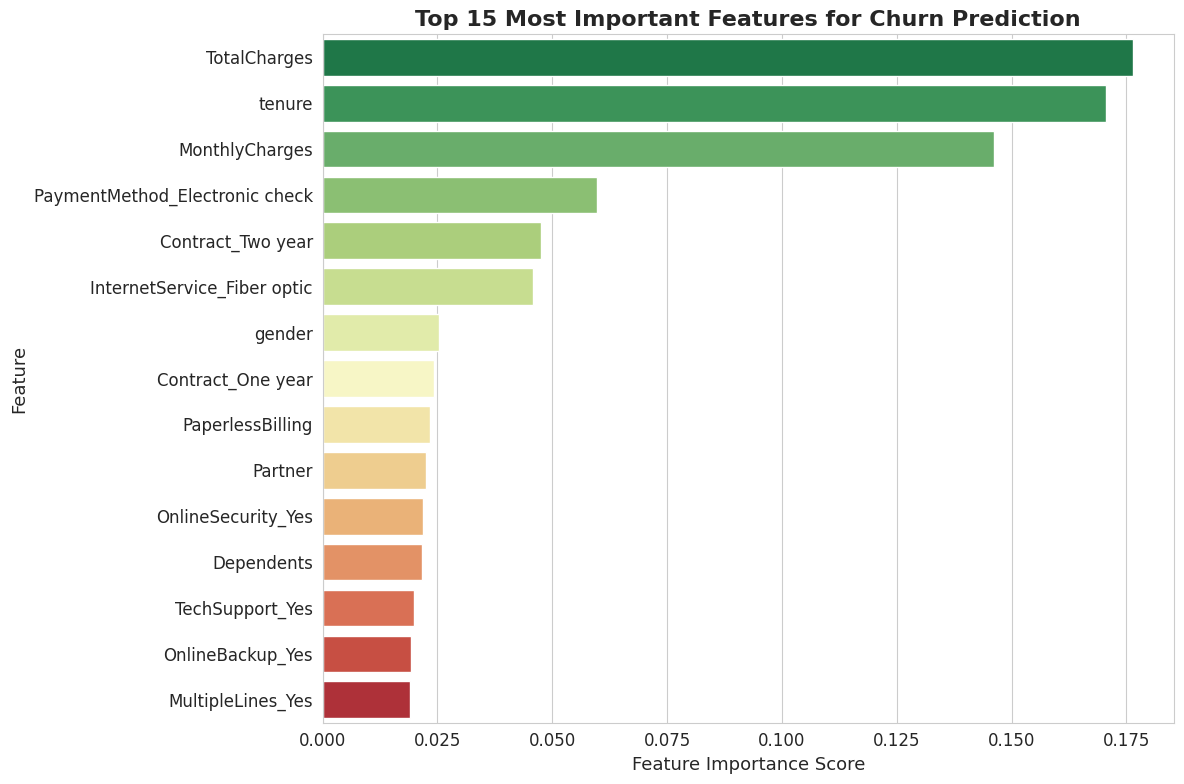

Plot saved!


In [71]:
# Plot Feature Importance
plt.figure(figsize=(12, 8))
sns.barplot(data=feature_importance.head(15),
            x='Importance', y='Feature',
            palette='RdYlGn_r')
plt.title('Top 15 Most Important Features for Churn Prediction',
          fontsize=16, fontweight='bold')
plt.xlabel('Feature Importance Score', fontsize=13)
plt.ylabel('Feature', fontsize=13)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

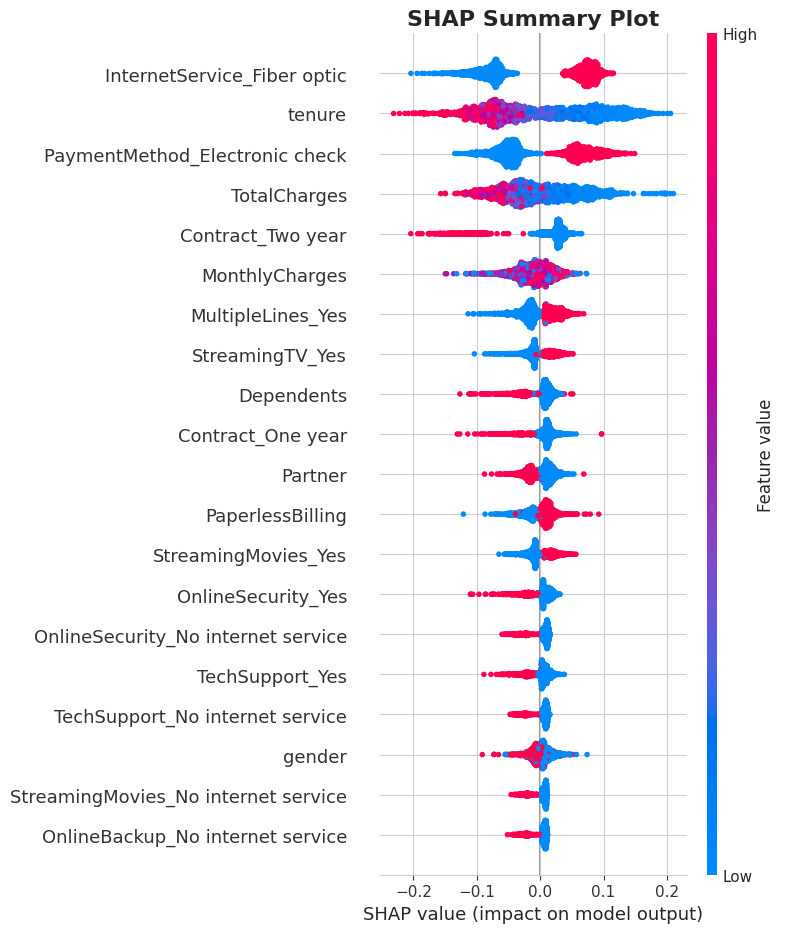

Plot saved!


In [73]:
# SHAP Analysis
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Summary Plot
plt.figure()
shap.summary_plot(shap_values[1], X_test,
                  feature_names=X_test.columns.tolist(),
                  show=False)
plt.title('SHAP Summary Plot', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

In [ ]:
# SHAP Analysis - Fixed
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Check shape
print("SHAP values type:", type(shap_values))
print("SHAP values shape:", shap_values.shape)

# Summary Plot - Fixed
plt.figure()
shap.summary_plot(shap_values[:, :, 1], X_test,
                  feature_names=X_test.columns.tolist(),
                  show=False)
plt.title('SHAP Summary Plot', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

In [74]:
# Business Recommendations
print("=" * 60)
print("BUSINESS RECOMMENDATIONS BASED ON DATA ANALYSIS")
print("=" * 60)

print("\n1. TARGET MONTH-TO-MONTH CUSTOMERS")
print("   Churn rate of 42.7% vs 2.8% for two year contracts.")
print("   Offer discounts to switch to annual or two year plans.")

print("\n2. FOCUS ON NEW CUSTOMERS (0-12 MONTHS)")
print("   47.7% churn rate in first year is critically high.")
print("   Implement strong onboarding program and first year rewards.")

print("\n3. ADDRESS FIBER OPTIC DISSATISFACTION")
print("   Fiber optic customers churn most despite premium pricing.")
print("   Investigate service quality and offer better value plans.")

print("\n4. CONVERT ELECTRONIC CHECK USERS")
print("   Electronic check users have highest churn rate.")
print("   Incentivize switch to automatic payments with discounts.")

print("\n5. SENIOR CITIZEN RETENTION PROGRAM")
print("   Senior citizens churn at 41.7% vs 23.6% for non-seniors.")
print("   Create dedicated support and special pricing for seniors.")

print("\n" + "=" * 60)
print("Best Model: Random Forest | ROC-AUC: 91.94%")
print("=" * 60)

BUSINESS RECOMMENDATIONS BASED ON DATA ANALYSIS

1. TARGET MONTH-TO-MONTH CUSTOMERS
   Churn rate of 42.7% vs 2.8% for two year contracts.
   Offer discounts to switch to annual or two year plans.

2. FOCUS ON NEW CUSTOMERS (0-12 MONTHS)
   47.7% churn rate in first year is critically high.
   Implement strong onboarding program and first year rewards.

3. ADDRESS FIBER OPTIC DISSATISFACTION
   Fiber optic customers churn most despite premium pricing.
   Investigate service quality and offer better value plans.

4. CONVERT ELECTRONIC CHECK USERS
   Electronic check users have highest churn rate.
   Incentivize switch to automatic payments with discounts.

5. SENIOR CITIZEN RETENTION PROGRAM
   Senior citizens churn at 41.7% vs 23.6% for non-seniors.
   Create dedicated support and special pricing for seniors.

Best Model: Random Forest | ROC-AUC: 91.94%


In [75]:
# Export cleaned data for Power BI
df_powerbi = pd.read_csv('/content/drive/MyDrive/ChurnProject/churn_data.csv.csv')

# Fix TotalCharges
df_powerbi['TotalCharges'] = pd.to_numeric(df_powerbi['TotalCharges'], errors='coerce')
df_powerbi['TotalCharges'].fillna(df_powerbi['TotalCharges'].median(), inplace=True)

# Add Tenure Group
df_powerbi['TenureGroup'] = pd.cut(df_powerbi['tenure'],
                            bins=[0, 12, 24, 48, 60, 72],
                            labels=['0-12 months', '12-24 months',
                                    '24-48 months', '48-60 months', '60-72 months'])

# Save to Google Drive
df_powerbi.to_csv('/content/drive/MyDrive/ChurnProject/churn_powerbi.csv', index=False)
print("File saved successfully!")
print("Shape:", df_powerbi.shape)
print("Columns:", df_powerbi.columns.tolist())

File saved successfully!
Shape: (7043, 22)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup']


In [76]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf, '/content/drive/MyDrive/ChurnProject/churn_model.pkl')

# Save the scaler
joblib.dump(scaler, '/content/drive/MyDrive/ChurnProject/scaler.pkl')

print("Model and scaler saved successfully!")


Model and scaler saved successfully!


In [77]:
import shutil
import os

# List of all saved images
images = [
    'churn_distribution.png',
    'churn_by_contract.png',
    'churn_by_internet_service.png',
    'churn_by_tenure.png',
    'monthly_charges_vs_churn.png',
    'correlation_heatmap.png',
    'churn_by_payment.png',
    'churn_rate_by_contract.png',
    'churn_rate_by_senior.png',
    'churn_rate_by_gender.png',
    'numerical_distributions.png',
    'churn_rate_by_tenure_group.png',
    'confusion_matrix.png',
    'roc_curve.png',
    'feature_importance.png',
    'shap_summary.png'
]

# Copy all images to Google Drive
for img in images:
    if os.path.exists(img):
        shutil.copy(img, f'/content/drive/MyDrive/ChurnProject/{img}')
        print(f"Saved: {img}")
    else:
        print(f"Missing: {img}")

Saved: churn_distribution.png
Saved: churn_by_contract.png
Saved: churn_by_internet_service.png
Saved: churn_by_tenure.png
Saved: monthly_charges_vs_churn.png
Saved: correlation_heatmap.png
Saved: churn_by_payment.png
Saved: churn_rate_by_contract.png
Saved: churn_rate_by_senior.png
Saved: churn_rate_by_gender.png
Saved: numerical_distributions.png
Saved: churn_rate_by_tenure_group.png
Saved: confusion_matrix.png
Saved: roc_curve.png
Saved: feature_importance.png
Saved: shap_summary.png
